1) Loading the Taxis Dataset

In [2]:
import seaborn as sns
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")
display(df)

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


2) Handling Missing Values

* Here we check for missing values in the dataset and identify columns with missing data.
* There are four categorical coloumns having missing values Payment,pickup_zone,dropoff_zone,pickup_zone,pickup_borough,dropoff_borough and replaced this missing values with mode value

In [11]:
print(df.isnull().sum())

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


* Impute missing values

* Missing values in the payment column is filled with the mode value
* Here the mode value is credit card , so replace the missing values with payment.

In [32]:
print(df['payment'].mode())

0    credit card
Name: payment, dtype: object


In [41]:
df['payment']=df['payment'].fillna(df['payment'].mode()[0])
display(df['payment'])

,payment
6203,cash
884,credit card
2882,credit card
4212,credit card
661,credit card
...,...
4220,credit card
2849,credit card
542,credit card
4067,credit card


In [42]:
print(df['payment'].isnull().sum())

0


In [34]:
print(df['payment'].value_counts())

payment
credit card    4577
cash           1812
Name: count, dtype: int64


* Missing values in the pickup_zone coloumn is filled with the mode value

In [35]:
df['pickup_zone']=df['pickup_zone'].fillna(df['pickup_zone'].mode()[0])
display(df['pickup_zone'])

,pickup_zone
6203,Old Astoria
884,Lincoln Square East
2882,East Chelsea
4212,West Village
661,Meatpacking/West Village West
...,...
4220,SoHo
2849,Midtown North
542,West Village
4067,Midtown East


In [36]:
print(df['pickup_zone'].isnull().sum())

0


* Imputing dropoff zone

In [37]:
df['dropoff_zone']=df['dropoff_zone'].fillna(df['dropoff_zone'].mode()[0])
print(df['dropoff_zone'].isnull().sum())
display(df['dropoff_zone'].value_counts())

0


,count
dropoff_zone,
Upper East Side North,290
Murray Hill,220
Midtown Center,215
Upper East Side South,177
Midtown East,176
...,...
Jamaica Estates,1
Madison,1
Douglaston,1


* Imputing-pickup_borough

In [38]:
df['pickup_borough']=df['pickup_borough'].fillna(df['pickup_borough'].mode()[0])
print(df['pickup_borough'].isnull().sum())

0


* Imputing-dropoff_borough

In [39]:
df['dropoff_borough']=df['dropoff_borough'].fillna(df['dropoff_borough'].mode()[0])
print(df['dropoff_borough'].isnull().sum())

0


In [43]:
print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


3) Visualizations using Matplotlib/Pandas Plot:

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

Line Chart

* The line plot shows how the fare changes according to pickup time.

In [28]:
df['pickup'] = pd.to_datetime(df['pickup'],errors='coerce') #here convert pickup into datetime


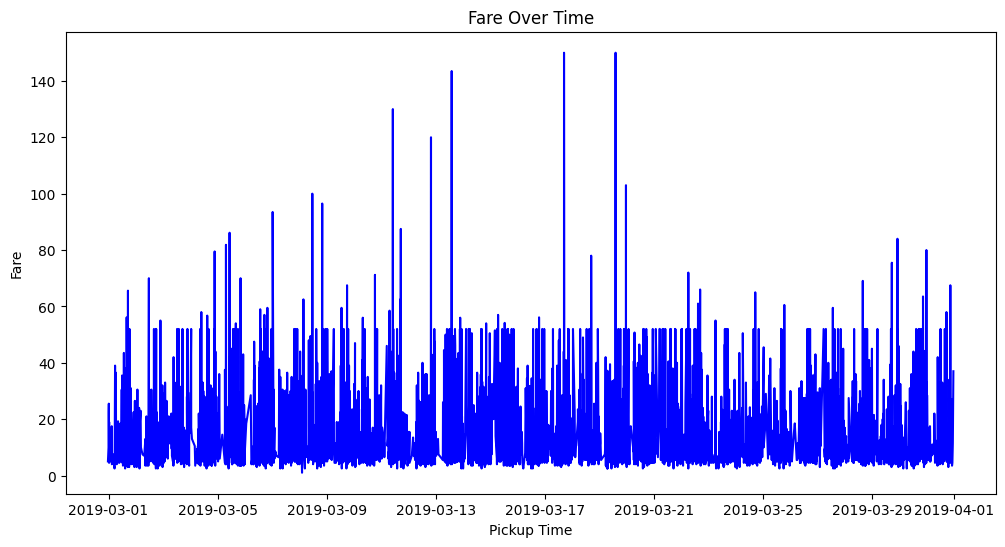

In [49]:
plt.figure(figsize=(12,6))


df = df.sort_values('pickup')
plt.plot(df['pickup'],df['fare'],'b')

plt.xlabel('Pickup Time')
plt.ylabel('Fare')
plt.title('Fare Over Time')

plt.show()

Bar Chart

* The bar chart compares fare amounts across different pickup boroughs, helping identify which borough has higher and lower fares.

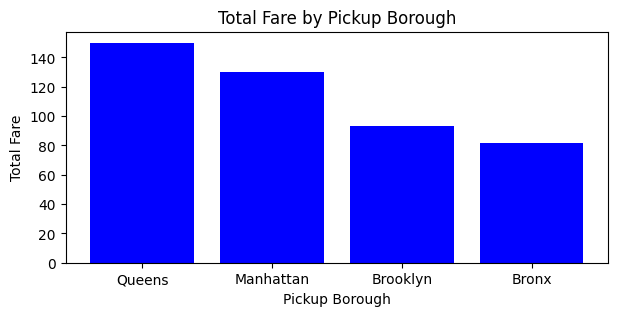

In [75]:
plt.figure(figsize=(7,3))

plt.bar(df['pickup_borough'],df['fare'],color='blue')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.title('Total Fare by Pickup Borough')

plt.show()

Pie chart
* The pie chart shows the percentage distribution of trips across different payment methods


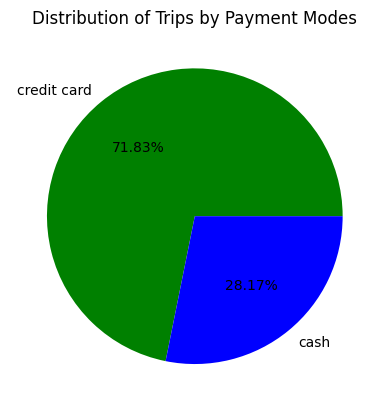

In [93]:
payments = df['payment'].value_counts()
plt.pie(payments, labels=payments.index,autopct='%1.2f%%',colors=['green','blue'])

plt.title('Distribution of Trips by Payment Modes')
plt.show()

Histogram
* The histogram shows how taxi trips are distributed across different distance ranges.

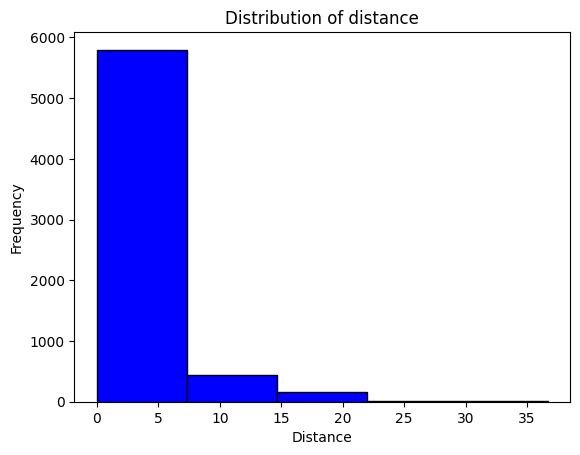

In [91]:
plt.hist(df['distance'], bins=5, color='blue',edgecolor='black')
plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.title('Distribution of distance')
plt.show()

Box plot
* The box plot compares tip amounts across different pickup boroughs, helping identify variations, median tips, and outliers.

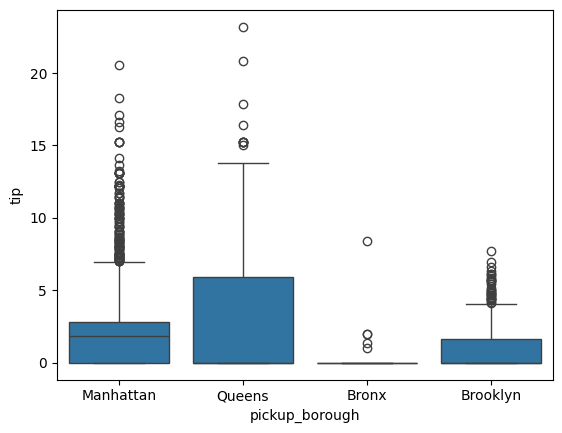

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.boxplot(x='pickup_borough', y='tip',data=df)
plt.show()


Visualizations using Seaborn:

Count plot
* Shows the number of taxi trips in each pickup borough
* From this count plot we can identify the borough with the highest and lowest number of trips

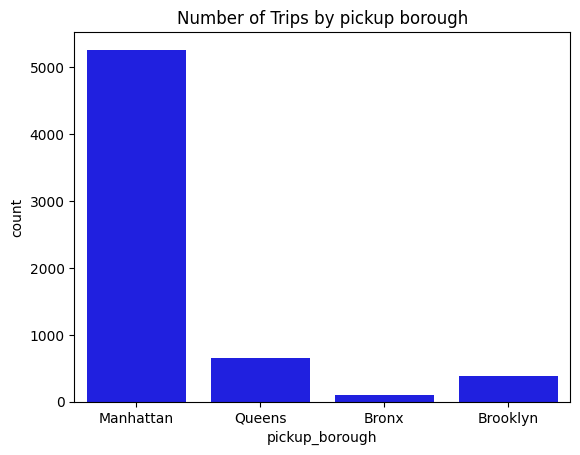

In [18]:
import seaborn as sns
sns.countplot(x='pickup_borough',data=df,color='blue')
plt.title('Number of Trips by pickup borough')
plt.show()


Scatter plot
* This scatter plot Shows the relationship between trip distance and fare amount
* From this graph we can identify that the longer trips have higher fares and different colours indicates the different pickup boroughs

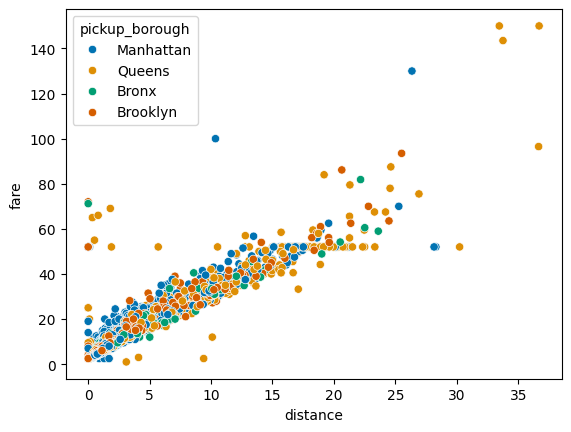

In [11]:
sns.scatterplot(x='distance',y='fare',data=df,hue='pickup_borough',palette='colorblind')
plt.show()

Heat map
* Here the heat map shows the correlation between differnt numeric variables distance, fare, tip, tolls, and total
* The values closer to +1 indicate a strong positive correlation, while values closer to -1 indicate a strong negative correlation.

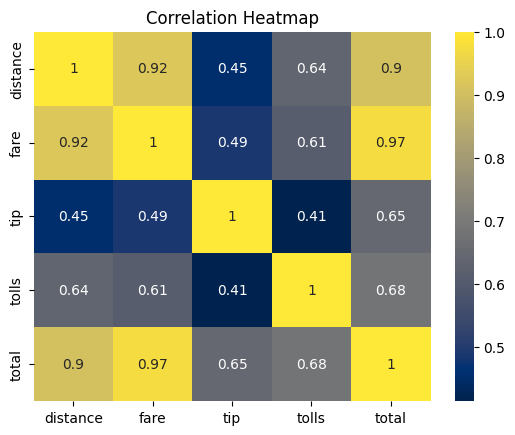

In [8]:
correalations=df[['distance', 'fare', 'tip', 'tolls', 'total']].corr()
sns.heatmap(correalations, annot=True, cmap='cividis')
plt.title('Correlation Heatmap')
plt.show()

Pair plot
* Here using multiple scatter charts create a pair plot and this pair plot show the pairwise relationships between distance, fare, tip, and total


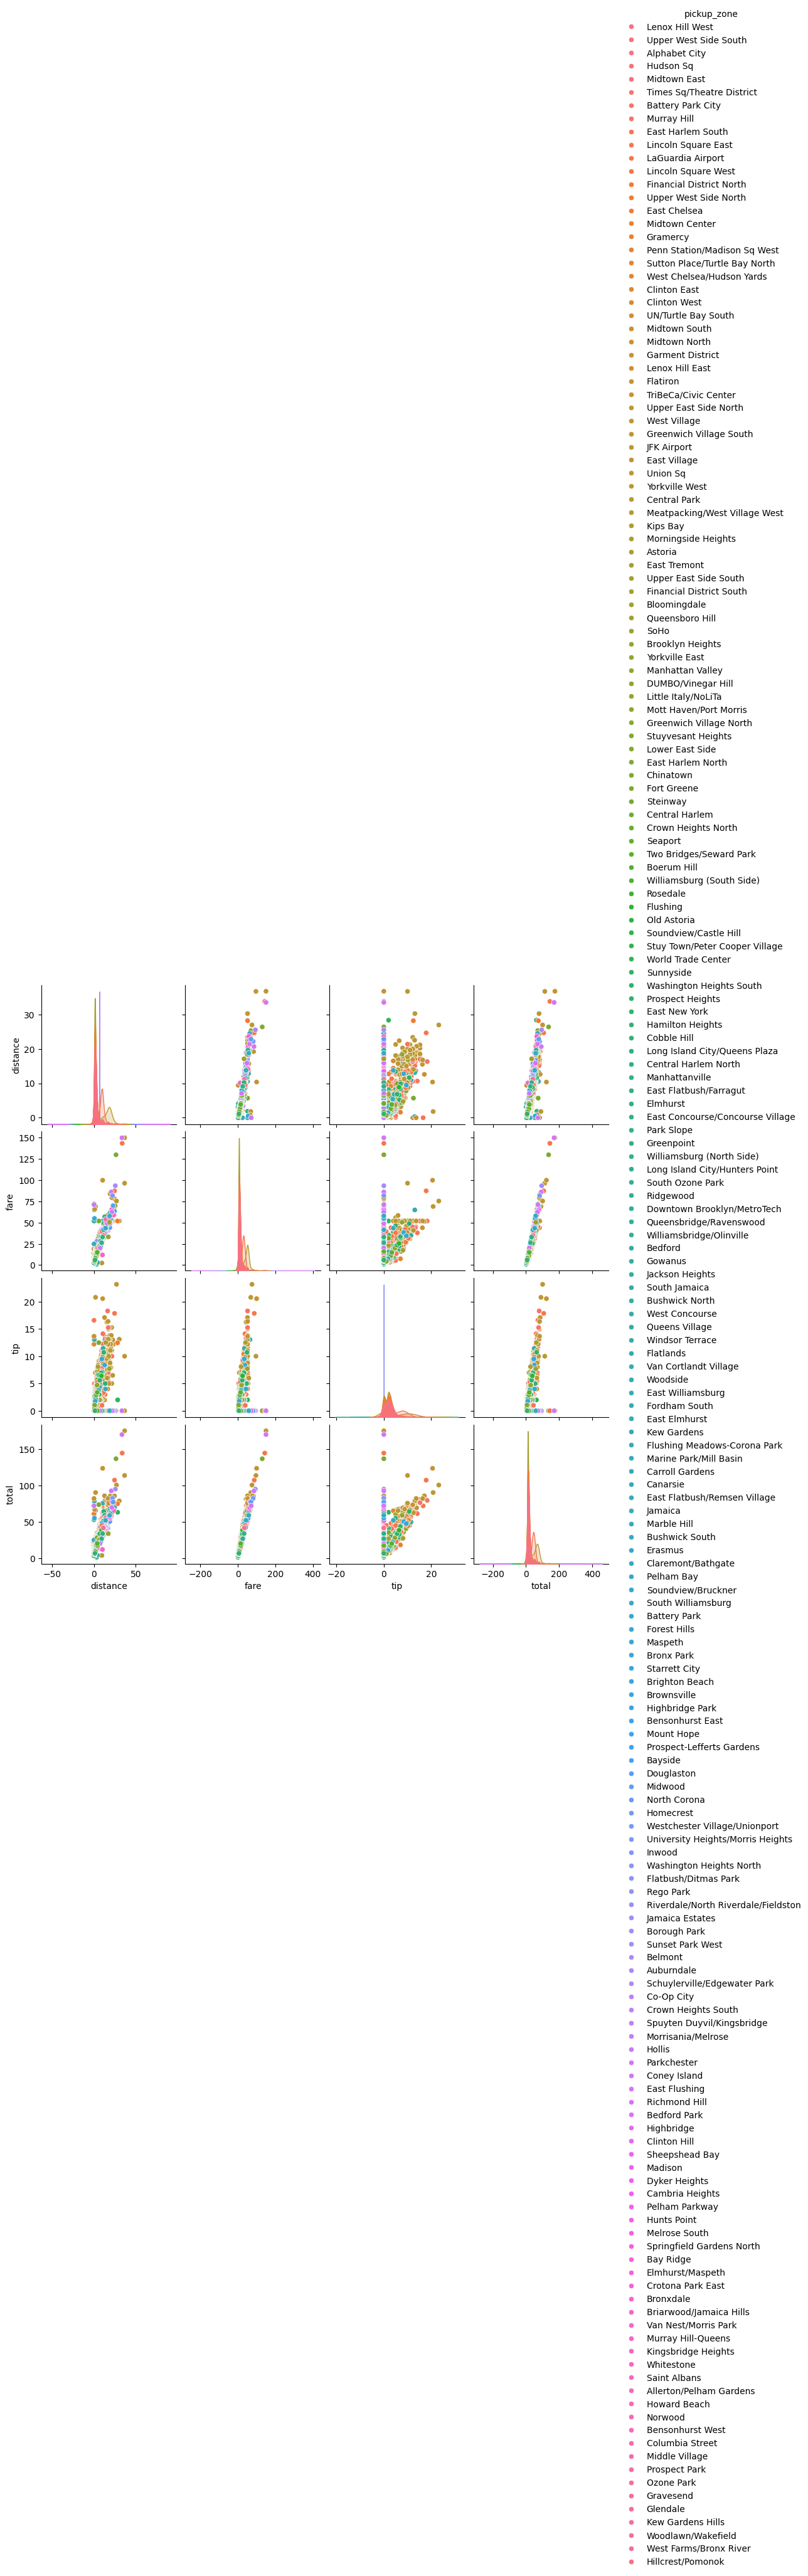

In [19]:
columns=df[['distance','fare','tip','total','pickup_zone']]
sns.pairplot(columns,hue='pickup_zone')
plt.show()

Violinpolt
* violin plot to show the distribution of fare amounts for different payment methods
* Bulge sections of the violin indicate where more fare values are concentrated

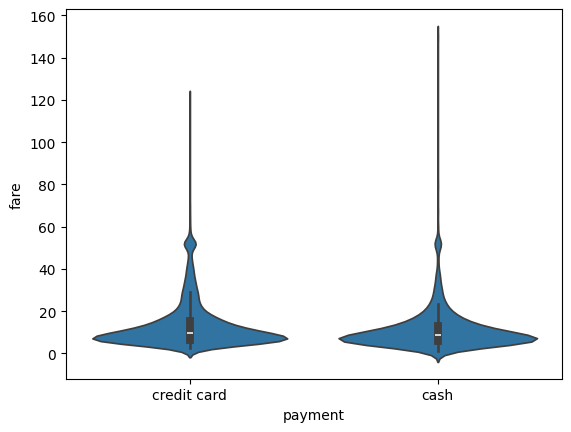

In [20]:
sns.violinplot(x='payment', y='fare', data=df)
plt.show()